# Lab 1.10 · Video generation inference

**15–20 minutes · CPU**

Read the [lab guide](README.md), then run the setup. Replace each `return None` with your implementation and rerun its check.

## Concepts and worked example

Why does a sequence of plausible frames sometimes look wrong in motion?

A video adds a time axis to the image grid. If adjacent frames disagree about the appearance of the same moving object, the resulting flicker is easy to see. Video generators can model relationships across time as part of generation. Temporal attention is one way to let information from other frames influence the current frame. A video latent has a time axis alongside its spatial axes. This exercise uses an aligned brightness trace to isolate one consequence of sharing information over time.

This lab uses a moving bright point on a one-dimensional strip. The point at column 1 in one frame moves to column 2 in the next. Comparing pixel changes at fixed coordinates mixes the intended movement with changes in brightness. Aligning by the known motion lets us track the same point across frames. For a brightness trace [0.8, 0.4, 0.8], averaging each entry with its neighbors yields [0.6, 0.667, 0.6]. Real models must infer motion and preserve details without the supplied positions.

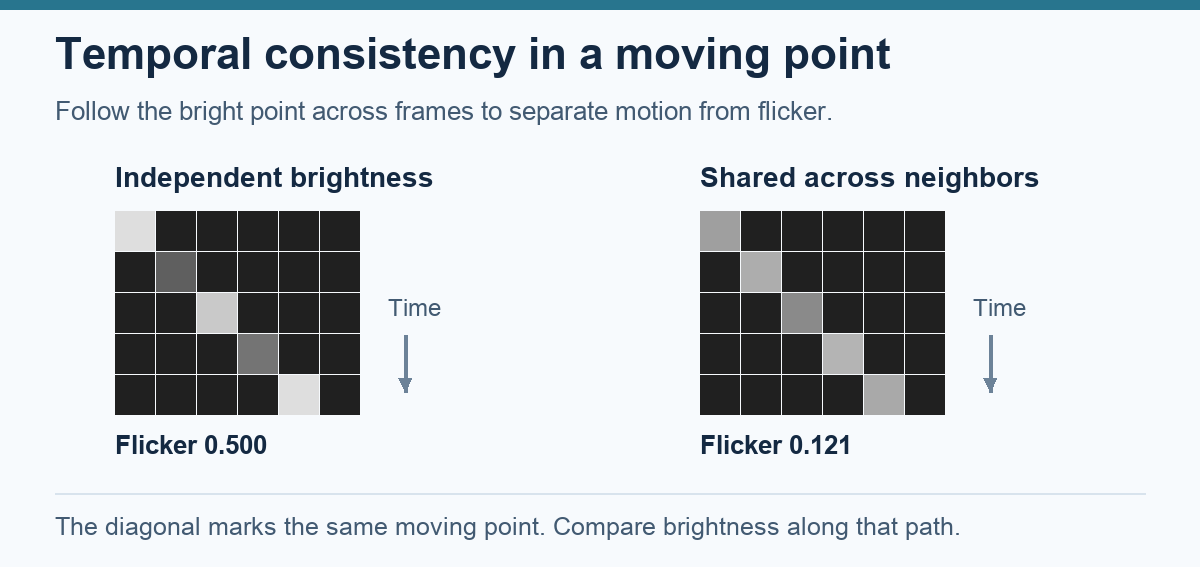

## Exercise map

| Exercise | What you will do | What to inspect |
| --- | --- | --- |
| 1. Measure flicker | Extract a motion-aligned trace and measure brightness changes. | Separate appearance changes from movement. |
| 2. Couple nearby frames | Smooth the aligned trace and rebuild the strip. | Check that flicker falls while the point keeps moving. |

In [ ]:
from math import isclose
from statistics import mean

positions = [0, 1, 2, 3, 4]
brightness = [0.9, 0.3, 0.8, 0.4, 0.9]
width = 6

def render(positions, levels, width):
    return [[level if x == position else 0.0 for x in range(width)]
            for position, level in zip(positions, levels)]

def show(clip):
    for frame, row in enumerate(clip):
        print(frame, " ".join(f"{value:.2f}" for value in row))

clip = render(positions, brightness, width)
show(clip)

## Exercise 1. Measure motion-aligned flicker

Read the brightness at the tracked position in each frame. Compute the mean absolute difference between consecutive brightness values. A constant trace should have zero flicker even when the point moves.

In [ ]:
def flicker(clip, positions):
    return None

In [ ]:
baseline = flicker(clip, positions)
if baseline is not None:
    assert isclose(baseline, 0.5)
    assert flicker(render(positions, [0.6] * 5, width), positions) == 0
    print("PASS — motion-aligned flicker:", baseline)

### Read the result

Use a constant-brightness moving point as a control. The metric should be zero even though image coordinates change.

## Exercise 2. Share brightness across neighboring frames

For each index, average its brightness with the previous and next entries that exist. Use the original trace for every average. Re-render using the original positions and compare the clip with the baseline.

In [ ]:
def smooth(levels):
    return None

In [ ]:
check_passed = False
levels = smooth(brightness)
if levels is not None and baseline is not None:
    assert all(isclose(a, b) for a, b in zip(smooth([0.8, 0.4, 0.8]), [0.6, 2/3, 0.6]))
    assert len(levels) == len(brightness)
    smoothed = render(positions, levels, width)
    assert [max(range(width), key=row.__getitem__) for row in smoothed] == positions
    assert flicker(smoothed, positions) < baseline
    show(smoothed)
    print("PASS — flicker after smoothing:", round(flicker(smoothed, positions), 3))
    check_passed = True
if not check_passed:
    print("Complete flicker and smooth and rerun the checks in order.")

### Read the result

Check both flicker and the brightest-pixel positions. A useful change should preserve the intended motion in this experiment.

## Compare your results

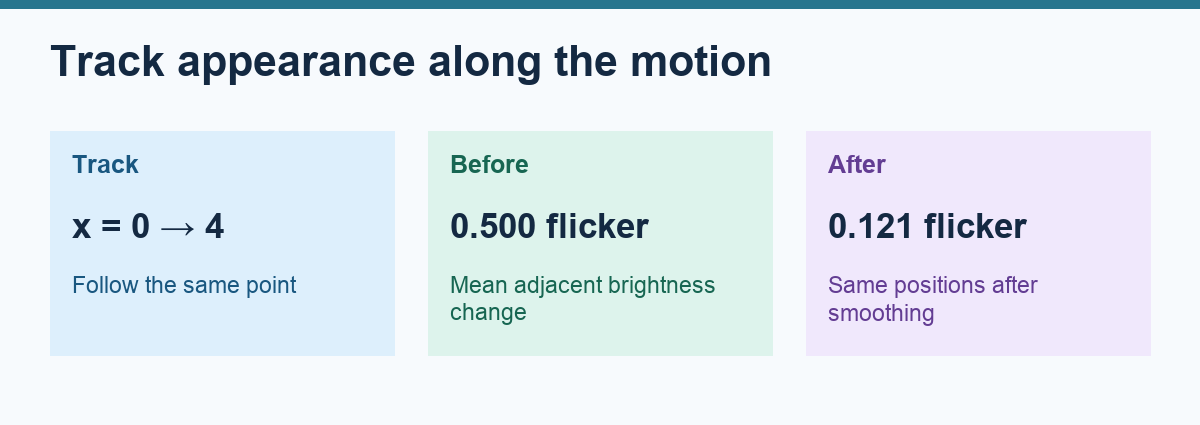

## Optional extension · Framewise drift and joint updates

Kiely contrasts framewise generation, where small errors can propagate into subsequent frames, with joint denoising over a video latent with spatial and temporal axes. In a joint approach, a denoising step can update the clip together. Attention that spans time lets cues from one frame affect another. Full attention over all space-time tokens is one possible design. Its query-key pair count grows with the square of the token count.

The aligned smoothing experiment demonstrates shared information over time with known motion. It has no learned attention. The extension simulates cumulative framewise drift and counts pairs for full attention, connecting the consistency benefit to the compute constraint described in the book.

Start at position 0 and compare the intended move of one pixel per frame with a framewise predictor that advances by 1.1 pixels. Predict the drift after eight updates. Then double the number of frames at a fixed number of spatial tokens per frame and compare the query-key pair counts.

Predict the result before you run the cell.

**Reading** · Philip Kiely, *Inference Engineering*, §2.3.3, pp. 59–60.

In [ ]:
from math import isclose

updates = 8
position = 0.0
for _ in range(updates):
    position += 1.1
drift = position - updates
assert isclose(drift, 0.8)
print("Final drift:", round(drift, 2))
spatial_tokens = 16
for frames in (4, 8):
    print(frames, "frames:", (frames * spatial_tokens) ** 2, "full-attention pairs")

## Wrap-up

Try a clip where the point should flash for exactly one frame. What information does smoothing erase? If a full attention operation treats T frames with S spatial tokens each as a single sequence, how does doubling T change the number of query-key pairs?

## Optional system exercise · Measuring the cost of extra frames

For full attention over a clip, keep spatial token count fixed and double the number of frames. Use the optional extension's pair count to estimate the change in work. Then propose a visual check that would catch oversmoothing of a deliberate flash.